<center><h1>Zhang_Zhengshu_HW3</h1></center>
<br>
<br>

Name: Zhengshu Zhang
<br>
Github Username: forestzs
<br>
USC ID: 4664738582

## 1. Time Series Classification Part 1: Feature Creation/Extraction

### (a) Download Data

Package imports

In [1]:
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 30)
pd.set_option("display.expand_frame_repr", False)

Get the AReM Data Set

The AReM data set has seven folders, one for each activity. Each file is one instance of a person performing the activity named by its folder. Each instance holds six time series named avg_rss12, var_rss12, avg_rss13, var_rss13, avg_rss23 and var_rss23. There are 88 instances, and each time series has 480 values recorded every 250 milliseconds over 120 seconds.

In [2]:
DATA_DIR = "data/AReM"
ACTIVITIES = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]


def dataset_number(file_name):
    """Return the number in a file name such as dataset12.csv."""
    return int(re.search("[0-9]+", file_name).group())


def csv_files(activity):
    """List the csv files of one activity folder in numeric order."""
    names = [name for name in os.listdir(f"{DATA_DIR}/{activity}") if name.endswith(".csv")]
    return sorted(names, key=dataset_number)


file_counts = pd.DataFrame({"activity": ACTIVITIES,
                            "files": [len(csv_files(activity)) for activity in ACTIVITIES]})
print(file_counts.to_string(index=False))
print("Total files:", file_counts["files"].sum())

activity  files
bending1      7
bending2      6
 cycling     15
   lying     15
 sitting     15
standing     15
 walking     15
Total files: 88


The six time series are numbered 1 to 6 in the order they appear in each file. Later parts of the homework refer to the time series by these numbers.

In [3]:
SERIES_NAMES = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

series_numbers = pd.DataFrame({"time series": range(1, 7), "name": SERIES_NAMES})
print(series_numbers.to_string(index=False))

 time series      name
           1 avg_rss12
           2 var_rss12
           3 avg_rss13
           4 var_rss13
           5 avg_rss23
           6 var_rss23


Four files need minor cleaning, and the read_instance function below fixes all four while reading them, so the files on disk stay unchanged. Treating commas and spaces alike fixes the space separators in bending2/dataset4.csv, and ignoring the empty value after the extra final comma fixes cycling/dataset9.csv and cycling/dataset14.csv. The file sitting/dataset8.csv has no row for time 13500, so its features are computed from the 479 rows that are present. The printed report also lists standing/dataset5.csv, whose one stray tab needs no cleaning.

In [4]:
EXPECTED_ROWS = 480
STEP_MS = 250


def data_lines(text):
    """Return (line number, line) for every line that is not blank and not a # header."""
    lines = []
    for number, line in enumerate(text.splitlines(), start=1):
        stripped = line.strip()
        if stripped and not stripped.startswith("#"):
            lines.append((number, line))
    return lines


def read_instance(path):
    """Read one file into a table of the six time series, indexed by time."""
    with open(path) as source:
        text = source.read()
    times, rows = [], []
    for number, line in data_lines(text):
        tokens = line.replace(",", " ").split()
        if len(tokens) != 7:
            raise ValueError(f"{path}, line {number}: expected 7 values, found {len(tokens)}")
        try:
            values = [float(token) for token in tokens]
        except ValueError:
            raise ValueError(f"{path}, line {number}: found a value that is not a number")
        times.append(int(values[0]))
        rows.append(values[1:])
    return pd.DataFrame(rows, columns=SERIES_NAMES, index=pd.Index(times, name="time"))


def row_count_problem(instance):
    """Describe a wrong row count, or return None when the instance has 480 rows."""
    if len(instance) == EXPECTED_ROWS:
        return None
    expected_times = set(range(0, EXPECTED_ROWS * STEP_MS, STEP_MS))
    missing = sorted(expected_times - set(instance.index))
    note = f"{len(instance)} rows instead of {EXPECTED_ROWS}"
    if missing:
        note += ", missing time " + " ".join(str(t) for t in missing)
    return note


def format_problems(path):
    """Describe separator and trailing-character problems found in the raw text.

    Also return whether a plain comma split fails, meaning some row does not give 7 fields.
    """
    with open(path) as source:
        lines = [line for _, line in data_lines(source.read())]
    problems = []
    no_comma = sum("," not in line for line in lines)
    trailing_space = sum(line != line.rstrip() for line in lines)
    trailing_comma = sum(line.rstrip().endswith(",") for line in lines)
    if no_comma:
        problems.append(f"{no_comma} of {len(lines)} rows use spaces instead of commas")
    if trailing_space:
        problems.append(f"{trailing_space} of {len(lines)} rows end with a space or tab")
    if trailing_comma:
        problems.append(f"{trailing_comma} of {len(lines)} rows end with an extra comma")
    comma_split_fails = any(len(line.split(",")) != 7 for line in lines)
    return problems, comma_split_fails

In [5]:
instances = []
cleaning_notes = []
whitespace_notes = []
for activity in ACTIVITIES:
    for file_name in csv_files(activity):
        path = f"{DATA_DIR}/{activity}/{file_name}"
        data = read_instance(path)
        problems, comma_split_fails = format_problems(path)
        row_note = row_count_problem(data)
        if row_note:
            problems.append(row_note)
        if comma_split_fails or row_note:
            cleaning_notes.append(f"{path}: " + ", ".join(problems))
        elif problems:
            whitespace_notes.append(f"{path}: " + ", ".join(problems))
        instances.append({"activity": activity, "file": file_name, "path": path, "data": data})

print("Instances loaded:", len(instances))
print("Files that needed cleaning:")
for note in cleaning_notes:
    print("  " + note)
print("Files with stray whitespace only, which needs no cleaning:")
for note in whitespace_notes:
    print("  " + note)

Instances loaded: 88
Files that needed cleaning:
  data/AReM/bending2/dataset4.csv: 480 of 480 rows use spaces instead of commas, 480 of 480 rows end with a space or tab
  data/AReM/cycling/dataset9.csv: 1 of 480 rows end with an extra comma
  data/AReM/cycling/dataset14.csv: 1 of 480 rows end with an extra comma
  data/AReM/sitting/dataset8.csv: 479 rows instead of 480, missing time 13500
Files with stray whitespace only, which needs no cleaning:
  data/AReM/standing/dataset5.csv: 1 of 480 rows end with a space or tab


### (b) Test and Train Data

The test data are instances dataset1 and dataset2 of bending1 and bending2, plus instances dataset1, dataset2 and dataset3 of the other five activities. All other instances are the train data. The split gives 19 test instances and 69 train instances.

In [6]:
def split_of(activity, file_name):
    """Return "test" or "train" for one dataset file, following the rule in 1(b)."""
    test_count = 2 if activity in ("bending1", "bending2") else 3
    return "test" if dataset_number(file_name) <= test_count else "train"

In [7]:
for item in instances:
    item["split"] = split_of(item["activity"], item["file"])

splits = [item["split"] for item in instances]
print("Train instances:", splits.count("train"))
print("Test instances:", splits.count("test"))
print()

split_table = pd.DataFrame({
    "activity": ACTIVITIES,
    "train": [sum(i["activity"] == a and i["split"] == "train" for i in instances) for a in ACTIVITIES],
    "test": [sum(i["activity"] == a and i["split"] == "test" for i in instances) for a in ACTIVITIES],
})
print(split_table.to_string(index=False))

Train instances: 69
Test instances: 19

activity  train  test
bending1      5     2
bending2      4     2
 cycling     12     3
   lying     12     3
 sitting     12     3
standing     12     3
 walking     12     3


### (c) Feature Extraction

#### i. Research

Time-domain features are summary numbers computed directly from the values of a time series. The table lists the time-domain features most often used for time series classification. Reference 13 gives a similar list for activity recognition.

| Feature | What it measures |
|---|---|
| Minimum | The smallest value in the time series |
| Maximum | The largest value in the time series |
| Range | The gap between the largest and smallest values |
| Mean | The average value |
| Median | The middle value after sorting the values |
| Standard deviation | How far the values typically spread around the mean |
| Variance | The square of the standard deviation |
| First quartile | The value below which a quarter of the values fall |
| Third quartile | The value below which three quarters of the values fall |
| Interquartile range | The spread of the middle half of the values |
| Root mean square | The typical size of the values, with large values counting more |
| Mean absolute deviation | The average distance of the values from the mean |
| Skewness | Whether the values lean more to one side of the mean |
| Kurtosis | How often values far from the mean appear |
| Zero-crossing rate | How often the time series changes sign |
| Mean-crossing rate | How often the time series crosses its own mean |
| Number of peaks | How many local high points the time series has |
| Signal energy | The sum of the squared values |
| Autocorrelation at lag one | How closely each value follows the value before it |
| Slope of a fitted straight line | Whether the time series trends up or down over time |
| Mean absolute change | The average size of the step from one value to the next |

Part 1(c)ii asks for seven features from the table, namely the minimum, maximum, mean, median, standard deviation, first quartile and third quartile. The seven features are computed for each of the six time series in every instance.

#### ii. Extraction

The feature table has one row for each of the 88 instances and one column for each of the 42 features. Each feature is one of the seven statistics of 1(c)ii computed on one of the six time series, and the seven statistics are called feature types from here on. Each column name joins a feature type and a time series number. For example, std_2 is the standard deviation of time series 2, and q1_6 is the first quartile of time series 6. The table also keeps four bookkeeping columns named instance, activity, source_file and split, which are not features.

In [8]:
FEATURES = ["min", "max", "mean", "median", "std", "q1", "q3"]
FEATURE_COLUMNS = [f"{feature}_{number}" for number in range(1, 7) for feature in FEATURES]
DDOF = 1  # sample standard deviation, used everywhere in this notebook


def series_features(values, ddof=DDOF):
    """Return the seven features of one time series in the order of FEATURES."""
    values = np.asarray(values, dtype=float)
    return [np.min(values), np.max(values), np.mean(values), np.median(values),
            np.std(values, ddof=ddof), np.percentile(values, 25), np.percentile(values, 75)]

In [9]:
rows = []
for number, item in enumerate(instances, start=1):
    row = {"instance": number, "activity": item["activity"],
           "source_file": item["path"], "split": item["split"]}
    for series_number, name in enumerate(SERIES_NAMES, start=1):
        for feature, value in zip(FEATURES, series_features(item["data"][name])):
            row[f"{feature}_{series_number}"] = value
    rows.append(row)

features = pd.DataFrame(rows, columns=["instance", "activity", "source_file", "split"] + FEATURE_COLUMNS)
print("Shape of the feature columns:", features[FEATURE_COLUMNS].shape)

Shape of the feature columns: (88, 42)


The feature table is too wide to print at once, so it is shown in six parts, one for each time series. The values shown are rounded to two decimals, while the table itself keeps full precision.

In [10]:
for number in range(1, 4):
    columns = [f"{feature}_{number}" for feature in FEATURES]
    display(features[["instance", "activity", "split"] + columns].head().round(2))

,instance,activity,split,min_1,max_1,mean_1,median_1,std_1,q1_1,q3_1
0,1,bending1,test,37.25,45.00,40.62,40.50,1.48,39.25,42.00
1,2,bending1,test,38.00,45.67,42.81,42.50,1.44,42.00,43.67
2,3,bending1,train,35.00,47.40,43.95,44.33,1.56,43.00,45.00
3,4,bending1,train,33.00,47.75,42.18,43.50,3.67,39.15,45.00
4,5,bending1,train,33.00,45.75,41.68,41.75,2.24,41.33,42.75


,instance,activity,split,min_2,max_2,mean_2,median_2,std_2,q1_2,q3_2
0,1,bending1,test,0.0,1.30,0.36,0.43,0.32,0.00,0.50
1,2,bending1,test,0.0,1.22,0.37,0.47,0.29,0.00,0.50
2,3,bending1,train,0.0,1.70,0.43,0.47,0.34,0.00,0.50
3,4,bending1,train,0.0,3.00,0.70,0.50,0.63,0.00,1.12
4,5,bending1,train,0.0,2.83,0.54,0.50,0.41,0.43,0.71


,instance,activity,split,min_3,max_3,mean_3,median_3,std_3,q1_3,q3_3
0,1,bending1,test,4.0,29.50,19.04,19.25,4.46,16.00,23.25
1,2,bending1,test,2.0,29.50,20.10,21.00,3.89,19.00,22.25
2,3,bending1,train,6.5,29.75,22.12,23.00,3.03,19.75,24.00
3,4,bending1,train,8.5,30.00,22.18,23.00,3.81,20.50,24.37
4,5,bending1,train,3.0,28.25,19.01,19.12,4.09,16.50,22.06


In [11]:
for number in range(4, 7):
    columns = [f"{feature}_{number}" for feature in FEATURES]
    display(features[["instance", "activity", "split"] + columns].head().round(2))

,instance,activity,split,min_4,max_4,mean_4,median_4,std_4,q1_4,q3_4
0,1,bending1,test,0.0,7.23,0.83,0.50,0.97,0.00,1.12
1,2,bending1,test,0.0,5.76,0.88,0.50,1.05,0.00,1.14
2,3,bending1,train,0.0,4.44,0.50,0.43,0.55,0.00,0.83
3,4,bending1,train,0.0,5.15,0.99,0.83,0.95,0.43,1.30
4,5,bending1,train,0.0,6.42,0.84,0.50,0.93,0.43,1.12


,instance,activity,split,min_5,max_5,mean_5,median_5,std_5,q1_5,q3_5
0,1,bending1,test,27.25,38.25,34.31,35.0,2.19,33.00,36.00
1,2,bending1,test,27.67,38.50,33.02,33.0,2.00,32.00,34.50
2,3,bending1,train,29.00,38.50,35.59,36.0,2.00,35.36,36.50
3,4,bending1,train,20.00,38.67,33.49,35.0,3.85,30.46,36.33
4,5,bending1,train,23.67,37.50,29.86,30.0,2.41,28.46,31.25


,instance,activity,split,min_6,max_6,mean_6,median_6,std_6,q1_6,q3_6
0,1,bending1,test,0.0,1.92,0.57,0.43,0.58,0.0,1.30
1,2,bending1,test,0.0,3.11,0.57,0.43,0.60,0.0,1.30
2,3,bending1,train,0.0,1.79,0.49,0.43,0.51,0.0,0.94
3,4,bending1,train,0.0,2.18,0.61,0.50,0.52,0.0,1.00
4,5,bending1,train,0.0,1.79,0.38,0.43,0.39,0.0,0.50


#### iii. Standard Deviation

The table below gives the standard deviation of each of the 42 features, together with a 90% bootstrap confidence interval. All 88 instances are used, because 1(c)iii asks about every feature extracted from the data. The bootstrap resamples the 88 instances with replacement 10000 times, recomputes each standard deviation every time, and keeps the middle 90% of the results as the interval. The random seed is fixed so that the numbers can be reproduced. A narrow interval means the standard deviation of a feature barely changes between resamples, while a wide interval means a few unusual instances can shift that standard deviation a lot.

In [12]:
N_BOOT = 10000
CI_PERCENTILES = (5, 95)  # the middle 90% of the bootstrap values


def bootstrap_std_ci(X, n_boot=N_BOOT, seed=0, percentiles=CI_PERCENTILES):
    """Bootstrap interval for the standard deviation of each column of X.

    Each replicate resamples the rows (instances) with replacement and uses the
    same rows for every column.
    """
    rng = np.random.default_rng(seed)
    n = X.shape[0]
    boot_stds = np.empty((n_boot, X.shape[1]))
    for b in range(n_boot):
        idx = rng.integers(0, n, size=n)
        boot_stds[b] = X[idx].std(axis=0, ddof=DDOF)
    lower = np.percentile(boot_stds, percentiles[0], axis=0)
    upper = np.percentile(boot_stds, percentiles[1], axis=0)
    return lower, upper

In [13]:
X = features[FEATURE_COLUMNS].to_numpy()
ci_lower, ci_upper = bootstrap_std_ci(X)

std_table = pd.DataFrame({"feature": FEATURE_COLUMNS,
                          "std": X.std(axis=0, ddof=DDOF),
                          "ci_lower": ci_lower,
                          "ci_upper": ci_upper})
print(std_table.round(4).to_string(index=False))

 feature    std  ci_lower  ci_upper
   min_1 9.5700    8.2569   10.7849
   max_1 4.3944    3.3435    5.2918
  mean_1 5.3357    4.7213    5.8777
median_1 5.4401    4.8068    6.0035
   std_1 1.7722    1.5716    1.9466
    q1_1 6.1536    5.5824    6.6483
    q3_1 5.1389    4.3421    5.8473
   min_2 0.0000    0.0000    0.0000
   max_2 5.0627    4.6258    5.4086
  mean_2 1.5742    1.3957    1.7053
median_2 1.4122    1.2367    1.5437
   std_2 0.8841    0.8034    0.9418
    q1_2 0.9464    0.8300    1.0350
    q3_2 2.1253    1.8932    2.2952
   min_3 2.9565    2.7564    3.1095
   max_3 4.8751    4.1941    5.4636
  mean_3 4.0084    3.4283    4.4992
median_3 4.0364    3.4424    4.5449
   std_3 0.9467    0.7647    1.1254
    q1_3 4.2207    3.6395    4.7070
    q3_3 4.1716    3.5567    4.7001
   min_4 0.0000    0.0000    0.0000
   max_4 2.1836    1.9759    2.3627
  mean_4 1.1661    1.0742    1.2225
median_4 1.1456    1.0536    1.2011
   std_4 0.4582    0.4208    0.4865
    q1_4 0.8436    0.7739   

#### iv. Select Features

The three most important feature types are chosen using the 69 train instances only, because choosing features is part of building a model and the test instances are kept aside. The choice is between the seven feature types min, max, mean, median, std, q1 and q3. Two pieces of evidence are used, namely how well each feature type separates the activities and how much two feature types carry the same information.

The first piece of evidence is separation. For each feature, the mean and the standard deviation of its values are computed over the train instances of each activity. The separation of the feature is the standard deviation of the seven means divided by the average of the seven standard deviations. A large separation means the activities sit far apart compared with how much the instances of one activity vary. The separation of a feature type is the average separation of its six features. The features min_2 and min_4 equal 0 for every train instance, so they cannot separate the activities and their separation is set to 0.

In [14]:
def separation(values, groups):
    """Spread of the activity means divided by the average spread within an activity."""
    if values.nunique() == 1:
        return 0.0  # a feature that never changes cannot separate the activities
    by_activity = values.groupby(groups)
    return by_activity.mean().std(ddof=DDOF) / by_activity.std(ddof=DDOF).mean()

In [15]:
train = features[features["split"] == "train"]

column_separation = pd.Series({column: separation(train[column], train["activity"])
                               for column in FEATURE_COLUMNS})
type_separation = pd.Series({feature: column_separation[[f"{feature}_{s}" for s in range(1, 7)]].mean()
                             for feature in FEATURES}, name="separation")
print(type_separation.round(3).to_frame().to_string())

        separation
min          0.969
max          1.651
mean         5.420
median       5.405
std          2.662
q1           3.916
q3           5.310


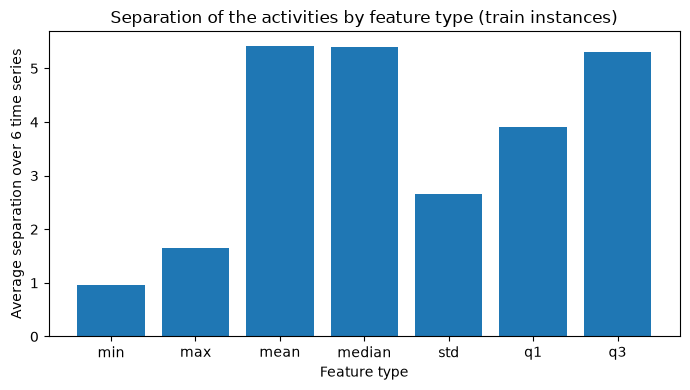

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(FEATURES, type_separation.values)
ax.set_title("Separation of the activities by feature type (train instances)")
ax.set_xlabel("Feature type")
ax.set_ylabel("Average separation over 6 time series")
fig.tight_layout()
plt.show()

The second piece of evidence is correlation. Two feature types with a high correlation carry nearly the same information, so choosing both adds little beyond choosing one. For each pair of feature types, the table gives the absolute correlation between their features on the same time series, averaged over the six time series. Correlation is not defined for min_2 and min_4 because they never change, so the min row and the min column average over the other four time series.

In [17]:
abs_corr = train[FEATURE_COLUMNS].corr().abs()

type_correlation = pd.DataFrame(index=FEATURES, columns=FEATURES, dtype=float)
for f in FEATURES:
    for g in FEATURES:
        pairs = [abs_corr.loc[f"{f}_{s}", f"{g}_{s}"] for s in range(1, 7)]
        type_correlation.loc[f, g] = np.nanmean(pairs)
print(type_correlation.round(2).to_string())

         min   max  mean  median   std    q1    q3
min     1.00  0.36  0.59    0.57  0.40  0.60  0.52
max     0.36  1.00  0.79    0.75  0.63  0.71  0.82
mean    0.59  0.79  1.00    0.99  0.60  0.98  0.98
median  0.57  0.75  0.99    1.00  0.61  0.98  0.96
std     0.40  0.63  0.60    0.61  1.00  0.66  0.57
q1      0.60  0.71  0.98    0.98  0.66  1.00  0.93
q3      0.52  0.82  0.98    0.96  0.57  0.93  1.00


The three chosen feature types are mean, std and max. Mean separates the activities best (5.42). Median, q1 and q3 are left out because their average correlation with mean is 0.98 or 0.99, so they carry nearly the same information as mean. Among the remaining feature types, std separates the activities best (2.66) and has a correlation of only 0.60 with mean. Max is preferred to min because min separates the activities worst (0.97), and a feature type that separates poorly does little to tell the activities apart. Max also overlaps less with mean and std, with average correlations of 0.79 and 0.63.

## 2. ISLR 3.7.4

In Exercise 3.7.4 of An Introduction to Statistical Learning (ISLR, reference 12), a linear regression and a cubic regression are fitted to the same 100 observations. The observations have one predictor and a quantitative response. The cubic regression adds squared and cubed terms of the predictor to the linear regression. Each part asks which regression has the lower residual sum of squares (RSS), either on the 100 train observations or on new test observations.

### (a) Linear Train

The cubic regression has the lower train RSS, or at worst the same. The linear regression is the cubic regression with the squared and cubed terms set to zero, so the cubic regression can always fit the train data at least as well. In practice the extra terms also fit some of the noise, so the train RSS of the cubic regression comes out lower. However, a lower train RSS does not show that the cubic regression is better.

### (b) Linear Test

The linear regression should have the lower test RSS. The true relationship is already a straight line, so the squared and cubed terms add nothing real. The extra terms only make the cubic regression follow the noise in the train data, so the cubic regression does worse on the test observations. Even so, the cubic regression could come out ahead by chance on a particular set of test observations.

### (c) Not Linear Train

The cubic regression again has the lower train RSS, or at worst the same, for the same reason as in part (a). The linear regression is still the cubic regression with the squared and cubed terms set to zero. The verdict does not depend on how far from linear the true relationship is, because the comparison only involves how well the two regressions fit the same train data.

### (d) Not Linear Testing

There is not enough information to tell which test RSS is lower. If the true relationship is only slightly curved, the linear regression can still win because it is less affected by noise in the train data. But if the true relationship is strongly curved, the cubic regression wins because it can follow the curve. Since we do not know how far from linear the true relationship is, neither answer can be ruled out.

## 3. ISLR 3.7.3 - Extra Practice 

The assignment lists ISLR 3.7.3 as extra practice, and its answers are not submitted.

## 3. ISLR 3.7.5 - Extra Practice 

The assignment lists ISLR 3.7.5 as extra practice, and its answers are not submitted.

## References

1. AReM data set, UCI Machine Learning Repository. https://archive.ics.uci.edu/ml/datasets/Activity+Recognition+system+based+on+Multisensor+data+fusion+%28AReM%29
2. NumPy documentation, numpy.min. https://numpy.org/doc/stable/reference/generated/numpy.min.html
3. NumPy documentation, numpy.max. https://numpy.org/doc/stable/reference/generated/numpy.max.html
4. NumPy documentation, numpy.mean. https://numpy.org/doc/stable/reference/generated/numpy.mean.html
5. NumPy documentation, numpy.median. https://numpy.org/doc/stable/reference/generated/numpy.median.html
6. NumPy documentation, numpy.std. https://numpy.org/doc/stable/reference/generated/numpy.std.html
7. NumPy documentation, numpy.percentile. https://numpy.org/doc/stable/reference/generated/numpy.percentile.html
8. NumPy documentation, random Generator and default_rng. https://numpy.org/doc/stable/reference/random/generator.html
9. NumPy documentation, numpy.random.Generator.integers. https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.integers.html
10. pandas documentation, pandas.DataFrame.corr. https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html
11. Matplotlib documentation, matplotlib.axes.Axes.bar. https://matplotlib.org/stable/api/_as_gen/matplotlib.axes.Axes.bar.html
12. G. James, D. Witten, T. Hastie and R. Tibshirani, An Introduction to Statistical Learning. https://www.statlearning.com/
13. F. Demrozi, G. Pravadelli, A. Bihorac and P. Rashidi, Human Activity Recognition using Inertial, Physiological and Environmental Sensors: A Comprehensive Survey. arXiv:2004.08821. https://arxiv.org/abs/2004.08821